# Time Series: Advanced Assignment Part 4
## Recovering Sinusoidal wave using RNN

Student Name(s): Ariful Islam Riane (3981886), Pedro Fernandez Tonso (3983781)

Group No: 19



### Load required packages

In [1]:
# Import the needed packages
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, SimpleRNN, Conv1D, MaxPooling1D, LSTM

I0000 00:00:1791720449.645394 2384114 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791720449.646055 2384114 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791720449.712884 2384114 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1791720451.996194 2384114 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791720451.997013 2384114 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
# Fix the random seed
np.random.seed(0)
keras.utils.set_random_seed(0)

In [3]:
# Set the length of the series
n=3000
t=np.arange(0,n)

### Generate Dataset
To generate dataset we will use the following function:
$f(t)=sin(0.02t)+cos(0.05t)+sin(0.06t)$  
The following is the graph of above. 
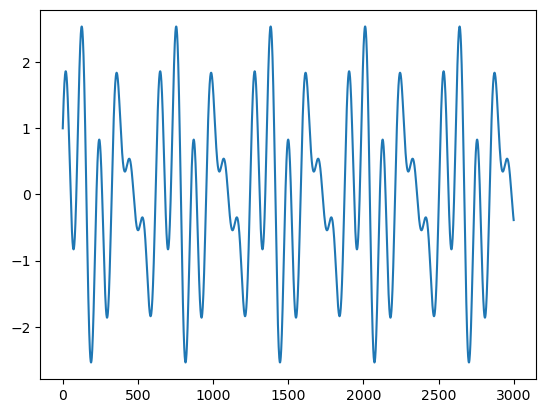

### Adding Noise
The data is very smooth. Your task is to add noise to data. You add noise by two ways:
- Uniform noise with low value -1 and hight value 1
- Noise generate using normal distribution

**Note:** You will have two different datasets so you need to train two different model for comparitive study. 

In [4]:
# Your code here
signal = np.sin(0.02*t) + np.cos(0.05*t) + np.sin(0.06*t)
# Same noise variance for both datasets (Var U(-1,1) = 1/3), so the comparison isolates the noise shape
noise_std = 1 / np.sqrt(3)
datasets = {
    'uniform': signal + np.random.uniform(low=-1, high=1, size=n),
    'normal': signal + np.random.normal(loc=0, scale=noise_std, size=n),
}
{name: round(float(np.std(y - signal)), 3) for name, y in datasets.items()}

{'uniform': 0.584, 'normal': 0.574}

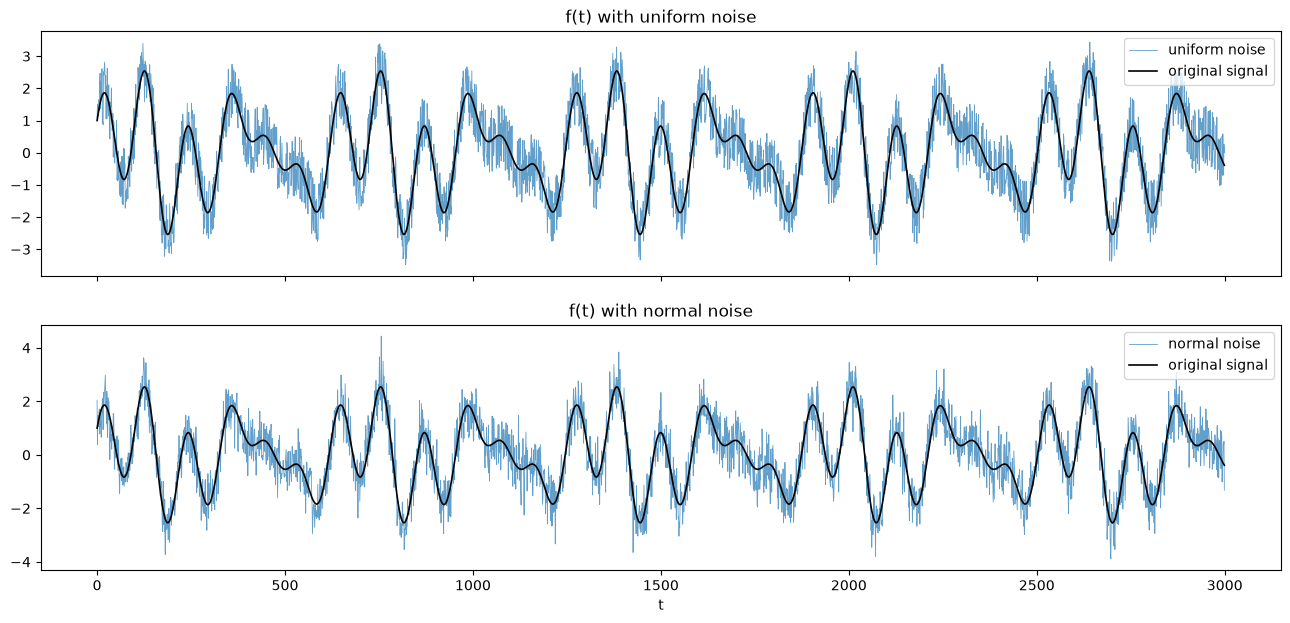

In [5]:
# Plot the original signal alog with noisy signal.
fig, axes = plt.subplots(2, 1, figsize=(16, 7), sharex=True)
for ax, (name, y) in zip(axes, datasets.items()):
    ax.plot(t, y, lw=0.6, alpha=0.7, label=f'{name} noise')
    ax.plot(t, signal, color='black', lw=1.2, label='original signal')
    ax.set_title(f'f(t) with {name} noise')
    ax.legend(loc='upper right')
axes[-1].set_xlabel('t')
plt.show()

In [6]:
# Normalize your data using minmax scalar
# The scaler is fit on the training part only, so no information from the test period leaks into training
split = int(0.8 * n)
scalers = {name: MinMaxScaler().fit(y[:split].reshape(-1, 1)) for name, y in datasets.items()}
scaled = {name: scalers[name].transform(y.reshape(-1, 1)).ravel() for name, y in datasets.items()}

In [7]:
# Split data into train and test set
# Chronological split: first 80% for training, last 20% for testing
splits = {name: (s[:split], s[split:]) for name, s in scaled.items()}
{name: (len(tr), len(te)) for name, (tr, te) in splits.items()}

{'uniform': (2400, 600), 'normal': (2400, 600)}

In [8]:
def createDataset(data, step):
    X, Y =[], []
    for i in range(len(data)-step): 
        X.append(data[i:i+step])
        Y.append(data[i+step])
    return np.array(X), np.array(Y)
 
step = 10
data = {}
for name, (train, test) in splits.items():
    trainX,trainY = createDataset(train,step)
    testX,testY = createDataset(test,step)
    # RNN layers expect [samples, timesteps, features]
    data[name] = (trainX[..., None], trainY, testX[..., None], testY)
print(data['uniform'][0][0].ravel())

[0.66530065 0.72507282 0.70344852 0.69724541 0.67218143 0.74642162
 0.69506152 0.83563988 0.86458598 0.70348676]


## RNN Model
Create a RNN model with the following paramters:
- Activation "tanh"
- Loss "mean squared error"
- optimizer "rmsprop"
- epochs 200
- batch size 16

In [9]:
# your code here
def build_rnn():
    model = Sequential([keras.Input(shape=(step, 1)),
                        SimpleRNN(32, activation='tanh'),
                        Dense(1)])
    model.compile(loss='mean_squared_error', optimizer='rmsprop')
    return model

def train(build, name):
    trainX, trainY, testX, testY = data[name]
    keras.utils.set_random_seed(0)
    model = build()
    t0 = time.time()
    history = model.fit(trainX, trainY, epochs=200, batch_size=16, validation_data=(testX, testY), verbose=0)
    return model, history, time.time() - t0

rnn = {name: train(build_rnn, name) for name in datasets}
rnn['uniform'][0].summary()
{name: f'{secs:.0f} s' for name, (_, _, secs) in rnn.items()}

E0000 00:00:1791720454.534304 2384114 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,244 (8.77 KB)

 Trainable params: 1,121 (4.38 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,123 (4.39 KB)

{'uniform': '207 s', 'normal': '172 s'}

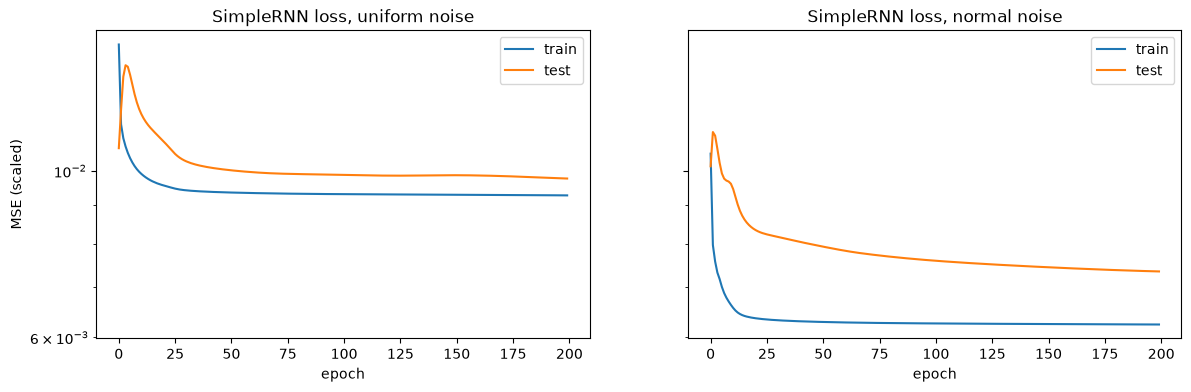

In [10]:
# Plot the loss
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, (name, (_, history, _)) in zip(axes, rnn.items()):
    ax.plot(history.history['loss'], label='train')
    ax.plot(history.history['val_loss'], label='test')
    ax.set_title(f'SimpleRNN loss, {name} noise')
    ax.set_xlabel('epoch')
    ax.set_yscale('log')
    ax.legend()
axes[0].set_ylabel('MSE (scaled)')
plt.show()

In [11]:
# Predict using test data
test_t = t[split + step:]
clean_test = signal[split + step:]

def predict(model, name):
    """Test predictions and noisy targets in the original units."""
    _, _, testX, testY = data[name]
    inv = lambda v: scalers[name].inverse_transform(v.reshape(-1, 1)).ravel()
    return inv(model.predict(testX, verbose=0)), inv(testY)

preds = {name: predict(model, name) for name, (model, _, _) in rnn.items()}

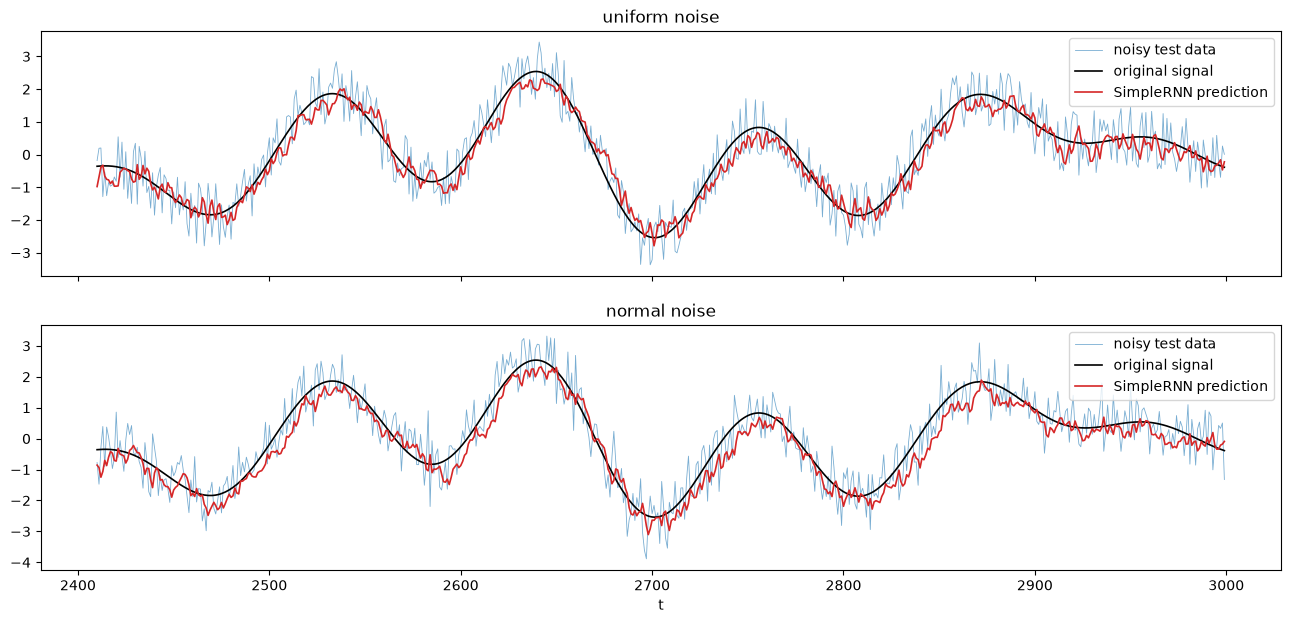

In [12]:
# Plot noisy data with the predicted data
fig, axes = plt.subplots(2, 1, figsize=(16, 7), sharex=True)
for ax, (name, (pred, noisy)) in zip(axes, preds.items()):
    ax.plot(test_t, noisy, lw=0.6, alpha=0.6, label='noisy test data')
    ax.plot(test_t, clean_test, color='black', lw=1.2, label='original signal')
    ax.plot(test_t, pred, color='tab:red', lw=1.2, label='SimpleRNN prediction')
    ax.set_title(f'{name} noise')
    ax.legend(loc='upper right')
axes[-1].set_xlabel('t')
plt.show()

## Compare model for different datasets
Now it is time to compare the models. You can compare them based on different criterion inclusing their accuracy, training time or any other criteria. 

In [13]:
def scores(pred, noisy, secs, history):
    return {'RMSE vs noisy data': np.sqrt(mean_squared_error(noisy, pred)),
            'RMSE vs original signal': np.sqrt(mean_squared_error(clean_test, pred)),
            'best test loss epoch': int(np.argmin(history.history['val_loss'])) + 1,
            'training time (s)': secs}

comparison = pd.DataFrame({f'SimpleRNN, {name} noise': scores(*preds[name], secs, history)
                           for name, (_, history, secs) in rnn.items()}).T
comparison['noise std (lower bound of RMSE vs noisy)'] = noise_std
comparison.round(3)

,RMSE vs noisy data,RMSE vs original signal,best test loss epoch,training time (s),noise std (lower bound of RMSE vs noisy)
"SimpleRNN, uniform noise",0.680,0.307,200.0,206.643,0.577
"SimpleRNN, normal noise",0.706,0.386,200.0,171.596,0.577


Both noises have the same standard deviation (0.577), so only their shape differs. The RMSE against the noisy data cannot go below that level, and the models reach 0.680 (uniform) and 0.706 (normal), or 0.307 and 0.386 against the clean signal. The gap is small and comes from a single noise draw. In both cases the prediction follows the sine, lags it slightly and undershoots the peaks.

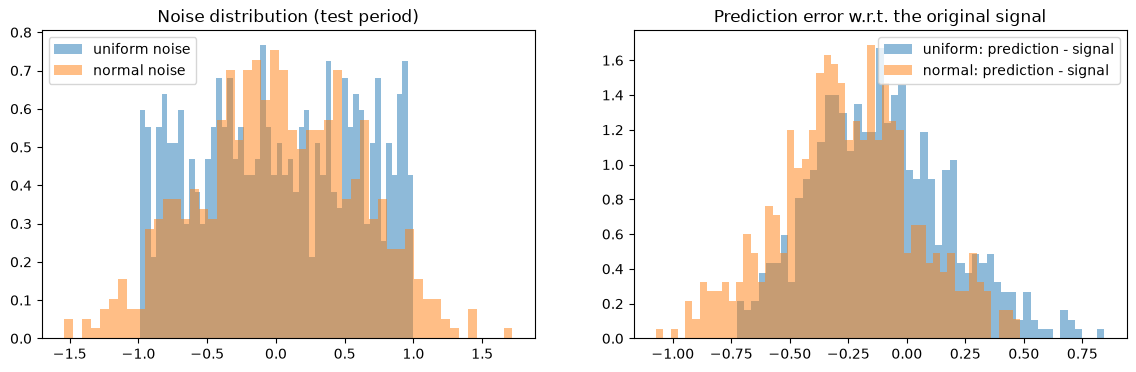

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for name, (pred, noisy) in preds.items():
    axes[0].hist(noisy - signal[split + step:], bins=50, alpha=0.5, density=True, label=f'{name} noise')
    axes[1].hist(pred - clean_test, bins=50, alpha=0.5, density=True, label=f'{name}: prediction - signal')
axes[0].set_title('Noise distribution (test period)')
axes[1].set_title('Prediction error w.r.t. the original signal')
for ax in axes: ax.legend()
plt.show()

## CNN LSTM
Repeat the exercises with the noisy data( only of the dataset should be sufficient). 

In [15]:
# Your code here(you might need more cells so add as many as you like)
# CNN-LSTM on the uniform-noise dataset: a 1D convolution extracts local features from the window,
# pooling halves the sequence and an LSTM models the remaining temporal dependence.
def build_cnn_lstm():
    model = Sequential([keras.Input(shape=(step, 1)),
                        Conv1D(filters=64, kernel_size=3, activation='relu'),
                        MaxPooling1D(pool_size=2),
                        LSTM(50, activation='tanh'),
                        Dense(1)])
    model.compile(loss='mean_squared_error', optimizer='rmsprop')
    return model

cnn_model, cnn_history, cnn_secs = train(build_cnn_lstm, 'uniform')
cnn_model.summary()
print(f'training time: {cnn_secs:.0f} s')

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 8, 64)          │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 4, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 50)             │        23,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 46,616 (182.10 KB)

 Trainable params: 23,307 (91.04 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 23,309 (91.05 KB)

training time: 266 s


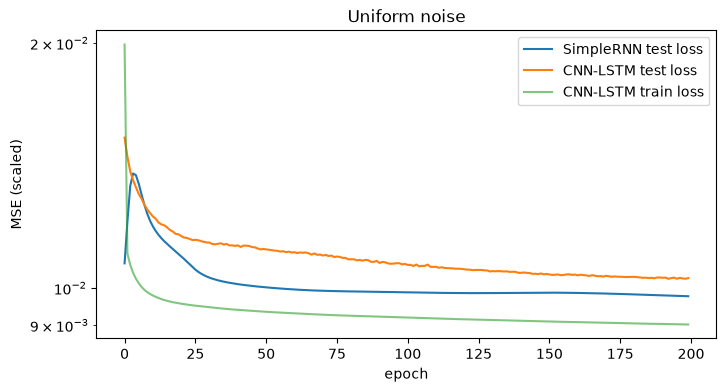

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(rnn['uniform'][1].history['val_loss'], label='SimpleRNN test loss')
ax.plot(cnn_history.history['val_loss'], label='CNN-LSTM test loss')
ax.plot(cnn_history.history['loss'], label='CNN-LSTM train loss', alpha=0.6)
ax.set_yscale('log')
ax.set_xlabel('epoch')
ax.set_ylabel('MSE (scaled)')
ax.set_title('Uniform noise')
ax.legend()
plt.show()

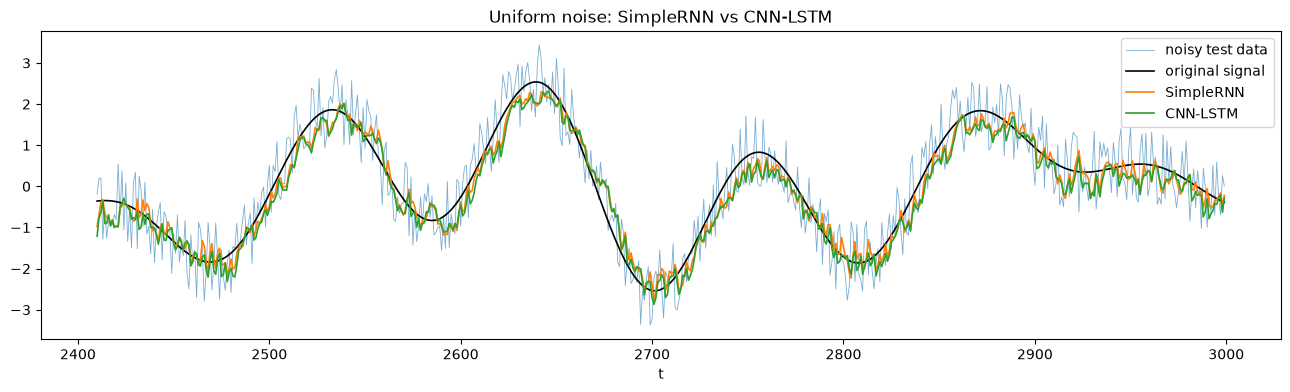

,RMSE vs noisy data,RMSE vs original signal,best test loss epoch,training time (s),noise std (lower bound of RMSE vs noisy),parameters
"SimpleRNN, uniform noise",0.680,0.307,200.0,206.643,0.577,1121
"SimpleRNN, normal noise",0.706,0.386,200.0,171.596,0.577,1121
"CNN-LSTM, uniform noise",0.698,0.341,193.0,265.852,0.577,23307


In [17]:
cnn_pred, noisy = predict(cnn_model, 'uniform')
fig, ax = plt.subplots(figsize=(16, 4))
ax.plot(test_t, noisy, lw=0.6, alpha=0.6, label='noisy test data')
ax.plot(test_t, clean_test, color='black', lw=1.2, label='original signal')
ax.plot(test_t, preds['uniform'][0], lw=1.2, label='SimpleRNN')
ax.plot(test_t, cnn_pred, lw=1.2, label='CNN-LSTM')
ax.set_xlabel('t')
ax.set_title('Uniform noise: SimpleRNN vs CNN-LSTM')
ax.legend(loc='upper right')
plt.show()

comparison.loc['CNN-LSTM, uniform noise'] = scores(cnn_pred, noisy, cnn_secs, cnn_history) | {'noise std (lower bound of RMSE vs noisy)': noise_std}
comparison.assign(parameters=[rnn['uniform'][0].count_params()] * 2 + [cnn_model.count_params()]).round(3)

The CNN-LSTM scores 0.341 against the clean signal (0.698 against the noisy data), slightly worse than the SimpleRNN (0.307 and 0.680), with 20 times the parameters and a longer training time. The signal is smooth, and with a window of ten points little is left for the convolution to extract. Results rest on one seed.